# Notebook 04 — Functional & Metabolic Enrichment
## GSE136666 — Substantia nigra: Parkinson vs Control

### Position in the project
This notebook takes the differential-expression output from **Notebook 03** and asks a higher-level biological question:

> **Which biological functions and metabolic pathways are systematically altered in Parkinson's disease substantia nigra?**

### Analysis layers
We use two complementary approaches:

1. **Rank-based enrichment / preranked GSEA**
   - Uses **all tested genes**.
   - Primary input: the signed Wald statistic from PyDESeq2.
   - Preferred because it does not depend on an arbitrary DEG threshold.

2. **Over-representation analysis (ORA)**
   - Uses thresholded gene lists.
   - Performed separately for genes increased and decreased in Parkinson's disease.
   - Treated as complementary to GSEA, not as the only pathway analysis.

### Functional libraries
The notebook is designed to query current Enrichr-compatible resources dynamically and prefers:
- Gene Ontology — Biological Process
- Gene Ontology — Molecular Function
- Reactome
- KEGG human pathways
- WikiPathways human
- MSigDB Hallmark

### Metabolic layer
A pathway is not called “metabolic” simply because Parkinson's disease is known to involve metabolism.  
Instead, significant enrichment results are screened using a transparent metabolic vocabulary and then organized into biological themes such as:
- mitochondrial respiration / oxidative phosphorylation
- TCA cycle
- glycolysis / pyruvate metabolism
- lipid and fatty-acid metabolism
- amino-acid metabolism
- glutathione / redox metabolism
- NAD / one-carbon metabolism
- dopamine / catecholamine metabolism
- mitochondrial transport and bioenergetics

### Scientific safeguards
- **Do not force a metabolic interpretation if enrichment is absent.**
- **Do not use the number of DEGs as an optimization target.**
- Multiple-testing correction is required.
- Up- and down-regulated ORA are kept separate.
- GSEA direction is interpreted from the sign of the enrichment score/NES.
- This notebook refuses to label results as final when Notebook 03 used the exploratory statistical fallback.

In [1]:
# 0. Imports and reproducibility
from pathlib import Path
import csv
import io
import json
import re
import sys
import platform
import importlib.util
import warnings
import urllib.request
import urllib.error

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import hypergeom
from statsmodels.stats.multitest import multipletests
from IPython.display import display

RANDOM_STATE = 42
ALPHA = 0.05
MIN_GENESET = 10
MAX_GENESET = 500
N_PERMUTATIONS = 1000

np.random.seed(RANDOM_STATE)

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("gseapy installed:", importlib.util.find_spec("gseapy") is not None)

Python: 3.13.5
Platform: Linux-6.18.44-x86_64-with-glibc2.41
pandas: 2.2.3
numpy: 2.3.5
gseapy installed: False


## Recommended environment

For the complete rank-based analysis, install **GSEApy**:

```bash
pip install gseapy
```

The notebook also contains:
- an internal ORA implementation based on the hypergeometric test;
- automatic NCBI Entrez Gene ID → gene symbol mapping using the GEO RNA-seq annotation table;
- automatic discovery of available Enrichr gene-set libraries.

Internet access is needed the first time annotation and gene-set libraries are downloaded.  
Downloaded resources are cached locally so subsequent runs are reproducible.

In [2]:
# 1. Project structure
PROJECT_ROOT = Path.cwd()

SEARCH_ROOTS = [
    PROJECT_ROOT,
    PROJECT_ROOT.parent,
    PROJECT_ROOT / "data",
    PROJECT_ROOT.parent / "data",
    Path("/mnt/data"),
]

RESULTS_DIR = PROJECT_ROOT / "results" / "functional_enrichment"
FIGURES_DIR = PROJECT_ROOT / "figures" / "functional_enrichment"
EXPORT_DIR = PROJECT_ROOT / "data" / "processed" / "notebook04"
CACHE_DIR = PROJECT_ROOT / "data" / "cache" / "enrichment"

for d in [RESULTS_DIR, FIGURES_DIR, EXPORT_DIR, CACHE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

def find_file(patterns):
    if isinstance(patterns, str):
        patterns = [patterns]
    matches = []
    for root in SEARCH_ROOTS:
        if not root.exists():
            continue
        for pattern in patterns:
            matches.extend(root.rglob(pattern))
    matches = sorted(set(p.resolve() for p in matches if p.is_file()))
    return matches[0] if matches else None

RANK_FILE = find_file("GSE136666_SN_ranked_statistic_for_GSEA.csv")
FULL_DE_FILE = find_file("GSE136666_SN_DE_full_results.csv")
DEG_FDR_FILE = find_file("GSE136666_SN_DE_FDR_lt_0.05.csv")
DEG_EFFECT_FILE = find_file("GSE136666_SN_DE_FDR_lt_0.05_absLFC_ge_1.csv")
MANIFEST_FILE = find_file("notebook03_manifest.json")

print("Ranking:", RANK_FILE)
print("Full DE:", FULL_DE_FILE)
print("FDR DEGs:", DEG_FDR_FILE)
print("Manifest:", MANIFEST_FILE)

assert RANK_FILE is not None, "Notebook 03 ranking file was not found."
assert FULL_DE_FILE is not None, "Notebook 03 full DE table was not found."
assert MANIFEST_FILE is not None, "Notebook 03 manifest was not found."

Ranking: /mnt/data/data/processed/notebook03/GSE136666_SN_ranked_statistic_for_GSEA.csv
Full DE: /mnt/data/data/processed/notebook03/GSE136666_SN_DE_full_results.csv
FDR DEGs: /mnt/data/data/processed/notebook03/GSE136666_SN_DE_FDR_lt_0.05.csv
Manifest: /mnt/data/data/processed/notebook03/notebook03_manifest.json


In [3]:
# 2. Read Notebook 03 provenance BEFORE running enrichment
with open(MANIFEST_FILE, "r", encoding="utf-8") as f:
    manifest03 = json.load(f)

display(pd.Series(manifest03, name="Notebook 03 provenance"))

RESULT_MODE = manifest03.get("result_mode", "UNKNOWN")
RANKING_METHOD = manifest03.get("ranking_method", "UNKNOWN")

AUTHORITATIVE_RANKING = RESULT_MODE == "PyDESeq2"

# Keep False for final thesis work.
# Change to True only if you intentionally want to inspect an exploratory
# enrichment before rerunning Notebook 03 with PyDESeq2.
RUN_EXPLORATORY_IF_NEEDED = False

if AUTHORITATIVE_RANKING:
    print("✓ Notebook 03 ranking comes from formal PyDESeq2 inference.")
elif RUN_EXPLORATORY_IF_NEEDED:
    warnings.warn(
        "Notebook 03 used the exploratory fallback. "
        "Enrichment will run but MUST be labeled exploratory."
    )
else:
    print(
        "⚠ Notebook 03 did not use PyDESeq2. "
        "Final enrichment will be blocked to prevent overinterpretation."
    )

RUN_ENRICHMENT = AUTHORITATIVE_RANKING or RUN_EXPLORATORY_IF_NEEDED
print("RUN_ENRICHMENT =", RUN_ENRICHMENT)

dataset                                                                GSE136666
tissue                                                          Substantia nigra
contrast                                                    Parkinson vs Control
n_samples                                                                     10
n_genes_tested                                                             22369
filter_rule_from_notebook02               count >= 10 in at least 3 SN libraries
primary_design                                                         ~ disease
sensitivity_design                                               ~ sex + disease
alpha                                                                       0.05
effect_cutoff_abs_log2FC                                                     1.0
result_mode                         EXPLORATORY_FALLBACK_NOT_FOR_FINAL_INFERENCE
ranking_method                 EXPLORATORY Welch statistic — replace after Py...
next_notebook               

⚠ Notebook 03 did not use PyDESeq2. Final enrichment will be blocked to prevent overinterpretation.
RUN_ENRICHMENT = False


### Why this gate matters

Notebook 03 may be executed in two modes:

- `PyDESeq2` → formal negative-binomial differential-expression inference.
- `EXPLORATORY_FALLBACK_NOT_FOR_FINAL_INFERENCE` → emergency descriptive ranking only.

Pathway analysis can amplify artifacts in a gene-level ranking. Therefore, the default behavior is conservative: **final enrichment only runs from the PyDESeq2 ranking**.

If you are still testing code structure, you can temporarily set:

```python
RUN_EXPLORATORY_IF_NEEDED = True
```

but those results must never be reported as final thesis findings.

In [4]:
# 3. Load and audit the differential-expression inputs
ranking_raw = pd.read_csv(RANK_FILE)
de_full = pd.read_csv(FULL_DE_FILE, index_col=0)
de_full.index = de_full.index.astype(str)

# Flexible handling of the first ranking column.
ranking_raw.columns = [str(c) for c in ranking_raw.columns]

if "GeneID" not in ranking_raw.columns:
    ranking_raw = ranking_raw.rename(columns={ranking_raw.columns[0]: "GeneID"})

if "ranking_statistic" not in ranking_raw.columns:
    numeric_candidates = [
        c for c in ranking_raw.columns
        if c != "GeneID" and pd.api.types.is_numeric_dtype(ranking_raw[c])
    ]
    assert numeric_candidates, "No numeric ranking statistic found."
    ranking_raw = ranking_raw.rename(
        columns={numeric_candidates[0]: "ranking_statistic"}
    )

ranking_raw["GeneID"] = ranking_raw["GeneID"].astype(str)
ranking_raw["ranking_statistic"] = pd.to_numeric(
    ranking_raw["ranking_statistic"],
    errors="coerce",
)

ranking_raw = (
    ranking_raw
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["GeneID", "ranking_statistic"])
)

print("Ranked genes:", len(ranking_raw))
print("Unique GeneIDs:", ranking_raw["GeneID"].nunique())
print("Ranking statistic range:",
      ranking_raw["ranking_statistic"].min(),
      "to",
      ranking_raw["ranking_statistic"].max())

display(ranking_raw.head(10))
display(ranking_raw.tail(10))

assert ranking_raw["GeneID"].nunique() == len(ranking_raw), (
    "GeneID duplicates found in ranked list."
)

Ranked genes: 22369
Unique GeneIDs: 22369
Ranking statistic range: -8.387254404111884 to 7.539117881092158


,GeneID,ranking_statistic
0,23235,7.539118
1,728024,7.156699
2,25800,6.734967
3,7771,6.679155
4,339287,6.647825
5,9738,6.266094
6,57474,6.244503
7,7716,6.235622
8,4204,6.193290
9,114044,6.125140


,GeneID,ranking_statistic
22359,8263,-5.989956
22360,7919,-6.204329
22361,662,-6.250399
22362,286122,-6.422282
22363,3763,-6.595003
22364,140701,-6.690048
22365,1345,-7.079116
22366,8933,-7.450468
22367,728039,-7.974482
22368,55658,-8.387254


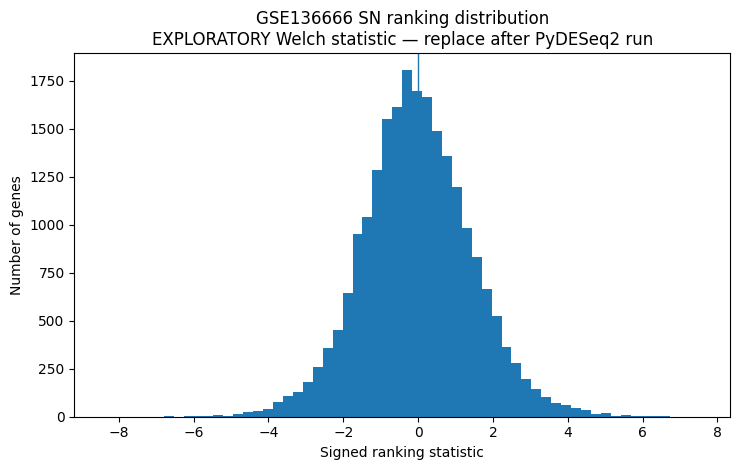

n_ranked_genes                                                22369
positive_statistics                                           10770
negative_statistics                                           11599
zero_statistics                                                   0
median_statistic                                          -0.066967
result_mode            EXPLORATORY_FALLBACK_NOT_FOR_FINAL_INFERENCE
dtype: object

In [5]:
# 4. Visual audit of the ranking distribution
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.hist(ranking_raw["ranking_statistic"], bins=60)
ax.axvline(0, linewidth=1)
ax.set_xlabel("Signed ranking statistic")
ax.set_ylabel("Number of genes")
ax.set_title(f"GSE136666 SN ranking distribution\n{RANKING_METHOD}")
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "GSE136666_SN_ranking_distribution.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

ranking_audit = pd.Series({
    "n_ranked_genes": len(ranking_raw),
    "positive_statistics": int((ranking_raw["ranking_statistic"] > 0).sum()),
    "negative_statistics": int((ranking_raw["ranking_statistic"] < 0).sum()),
    "zero_statistics": int((ranking_raw["ranking_statistic"] == 0).sum()),
    "median_statistic": float(ranking_raw["ranking_statistic"].median()),
    "result_mode": RESULT_MODE,
})
display(ranking_audit)

# Part A — Entrez Gene ID → Human gene symbol mapping

The NCBI-generated GSE136666 count matrix uses **Entrez Gene IDs**.  
Most Enrichr/GSEA libraries use **HGNC-style gene symbols**, so identifier mapping is required.

We use the same NCBI human annotation resource associated with GEO RNA-seq count downloads:

`Human.GRCh38.p13.annot.tsv.gz`

This preserves consistency with the NCBI-generated GRCh38.p13 count matrix.

If a local annotation file already exists, it is used first. Otherwise, the notebook downloads and caches it.

In [6]:
# 5. Find or download NCBI human annotation
ANNOT_LOCAL = find_file([
    "Human.GRCh38.p13.annot.tsv",
    "Human.GRCh38.p13.annot.tsv.gz",
    "*GRCh38.p13*annot*.tsv",
    "*GRCh38.p13*annot*.tsv.gz",
])

ANNOT_URL = (
    "https://www.ncbi.nlm.nih.gov/geo/download/"
    "?format=file&type=rnaseq_counts&file=Human.GRCh38.p13.annot.tsv.gz"
)

ANNOT_CACHE = CACHE_DIR / "Human.GRCh38.p13.annot.tsv.gz"

def download_file(url, destination):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading:", url)
    urllib.request.urlretrieve(url, destination)
    return destination

annotation_path = ANNOT_LOCAL

if annotation_path is None and ANNOT_CACHE.exists():
    annotation_path = ANNOT_CACHE

if annotation_path is None and RUN_ENRICHMENT:
    try:
        annotation_path = download_file(ANNOT_URL, ANNOT_CACHE)
    except Exception as exc:
        warnings.warn(
            "Could not download NCBI annotation. "
            f"Internet access may be unavailable. Details: {exc}"
        )

print("Annotation path:", annotation_path)

Annotation path: None


In [7]:
# 6. Parse annotation and construct a one-to-one readable mapping
gene_annotation = None
gene_map = None

if annotation_path is not None and Path(annotation_path).exists():
    gene_annotation = pd.read_csv(
        annotation_path,
        sep="\t",
        compression="infer",
        dtype=str,
        low_memory=False,
    )

    print("Annotation shape:", gene_annotation.shape)
    print("Columns:", gene_annotation.columns.tolist())

    required = {"GeneID", "Symbol"}
    missing = required - set(gene_annotation.columns)
    assert not missing, f"Annotation missing columns: {missing}"

    gene_annotation["GeneID"] = gene_annotation["GeneID"].astype(str)
    gene_annotation["Symbol"] = (
        gene_annotation["Symbol"]
        .astype(str)
        .replace({"nan": np.nan, "-": np.nan, "": np.nan})
    )

    gene_map = (
        gene_annotation[["GeneID", "Symbol"]]
        .dropna()
        .drop_duplicates(subset=["GeneID"], keep="first")
        .set_index("GeneID")["Symbol"]
    )

    mapping_qc = pd.Series({
        "annotation_rows": len(gene_annotation),
        "unique_annotated_GeneIDs": gene_map.index.nunique(),
        "ranked_GeneIDs": ranking_raw["GeneID"].nunique(),
        "ranked_GeneIDs_mapped": ranking_raw["GeneID"].isin(gene_map.index).sum(),
    })
    mapping_qc["mapping_fraction"] = (
        mapping_qc["ranked_GeneIDs_mapped"] /
        mapping_qc["ranked_GeneIDs"]
    )

    display(mapping_qc)
else:
    print(
        "Annotation not loaded. Mapping-dependent enrichment steps "
        "will remain pending until annotation is available."
    )

Annotation not loaded. Mapping-dependent enrichment steps will remain pending until annotation is available.


In [8]:
# 7. Map the full ranked list to symbols and resolve symbol duplicates
ranked_symbols = None
de_annotated = de_full.copy()

if gene_map is not None:
    rank_mapped = ranking_raw.copy()
    rank_mapped["Symbol"] = rank_mapped["GeneID"].map(gene_map)
    rank_mapped = rank_mapped.dropna(subset=["Symbol"]).copy()

    # Some Entrez IDs can map to the same symbol.
    # Keep the entry with the largest absolute ranking statistic.
    rank_mapped["abs_rank"] = rank_mapped["ranking_statistic"].abs()
    rank_mapped = (
        rank_mapped
        .sort_values("abs_rank", ascending=False)
        .drop_duplicates(subset=["Symbol"], keep="first")
        .sort_values("ranking_statistic", ascending=False)
    )

    ranked_symbols = (
        rank_mapped[["Symbol", "ranking_statistic"]]
        .set_index("Symbol")
    )

    de_annotated["Symbol"] = de_annotated.index.map(gene_map)

    symbol_qc = pd.Series({
        "mapped_ranked_rows_before_symbol_dedup": int(
            ranking_raw["GeneID"].isin(gene_map.index).sum()
        ),
        "unique_symbols_after_dedup": len(ranked_symbols),
        "symbols_with_positive_rank": int(
            (ranked_symbols["ranking_statistic"] > 0).sum()
        ),
        "symbols_with_negative_rank": int(
            (ranked_symbols["ranking_statistic"] < 0).sum()
        ),
    })
    display(symbol_qc)
    display(ranked_symbols.head(10))

# Part B — Current gene-set library discovery

Rather than hard-coding only one historical library name, the notebook queries the Enrichr library catalog and selects the best available match.

Preferred families:
- GO Biological Process
- GO Molecular Function
- Reactome
- KEGG Human
- WikiPathways Human
- MSigDB Hallmark

This makes the workflow more resistant to future library-version changes.

In [9]:
# 8. Query available Enrichr libraries
ENRICHR_STATS_URL = "https://maayanlab.cloud/Enrichr/datasetStatistics"
ENRICHR_GMT_URL = (
    "https://maayanlab.cloud/Enrichr/geneSetLibrary"
    "?mode=text&libraryName={library}"
)

available_libraries = []

if RUN_ENRICHMENT:
    try:
        with urllib.request.urlopen(ENRICHR_STATS_URL, timeout=30) as response:
            payload = json.loads(response.read().decode("utf-8"))

        if isinstance(payload, dict) and "statistics" in payload:
            stats = payload["statistics"]
        else:
            stats = payload

        for item in stats:
            name = item.get("libraryName") or item.get("library_name")
            if name:
                available_libraries.append(name)

        available_libraries = sorted(set(available_libraries))
        print("Available Enrichr libraries:", len(available_libraries))
    except Exception as exc:
        warnings.warn(
            "Could not query Enrichr library catalog. "
            f"Details: {exc}"
        )
else:
    print("External library query skipped because RUN_ENRICHMENT=False.")

External library query skipped because RUN_ENRICHMENT=False.


In [10]:
# 9. Resolve best available library names
PREFERENCES = {
    "GO_BP": [
        "GO_Biological_Process_2026",
        "GO_Biological_Process_2025",
        "GO_Biological_Process_2023",
        "GO_Biological_Process_2021",
    ],
    "GO_MF": [
        "GO_Molecular_Function_2026",
        "GO_Molecular_Function_2025",
        "GO_Molecular_Function_2023",
        "GO_Molecular_Function_2021",
    ],
    "Reactome": [
        "Reactome_Pathways_2024",
        "Reactome_2022",
        "Reactome_2016",
    ],
    "KEGG": [
        "KEGG_2026",
        "KEGG_2021_Human",
        "KEGG_2019_Human",
    ],
    "WikiPathways": [
        "WikiPathway_2025_Human",
        "WikiPathways_2024_Human",
        "WikiPathways_2023_Human",
        "WikiPathways_2019_Human",
    ],
    "Hallmark": [
        "MSigDB_Hallmark_2020",
    ],
}

def choose_library(candidates, available):
    for candidate in candidates:
        if candidate in available:
            return candidate
    return None

selected_libraries = {
    family: choose_library(candidates, available_libraries)
    for family, candidates in PREFERENCES.items()
}

library_table = pd.DataFrame({
    "family": list(selected_libraries.keys()),
    "selected_library": list(selected_libraries.values()),
})

display(library_table)

,family,selected_library
0,GO_BP,None
1,GO_MF,None
2,Reactome,None
3,KEGG,None
4,WikiPathways,None
5,Hallmark,None


In [11]:
# 10. Download/cache selected gene-set libraries as GMT-like dictionaries
def parse_enrichr_gmt_text(text):
    gene_sets = {}
    for line in text.splitlines():
        parts = line.rstrip("\n").split("\t")
        if len(parts) < 3:
            continue
        term = parts[0]
        genes = [g for g in parts[2:] if g]
        if genes:
            gene_sets[term] = genes
    return gene_sets

def get_library_gene_sets(library_name):
    cache_path = CACHE_DIR / f"{library_name}.gmt"

    if cache_path.exists():
        text = cache_path.read_text(encoding="utf-8")
        return parse_enrichr_gmt_text(text)

    url = ENRICHR_GMT_URL.format(library=library_name)
    with urllib.request.urlopen(url, timeout=60) as response:
        text = response.read().decode("utf-8")

    cache_path.write_text(text, encoding="utf-8")
    return parse_enrichr_gmt_text(text)

gene_set_libraries = {}

if RUN_ENRICHMENT and ranked_symbols is not None:
    for family, library_name in selected_libraries.items():
        if library_name is None:
            print(f"Skipping {family}: no compatible library resolved.")
            continue
        try:
            gs = get_library_gene_sets(library_name)
            gene_set_libraries[family] = gs
            print(f"{family}: {library_name} — {len(gs):,} gene sets")
        except Exception as exc:
            warnings.warn(f"Could not retrieve {library_name}: {exc}")
else:
    print("Gene-set download skipped.")

Gene-set download skipped.


# Part C — Preranked GSEA

### Primary enrichment analysis

For the definitive run, the ranking should be the **PyDESeq2 Wald statistic**:

- positive statistic → higher expression in Parkinson's disease
- negative statistic → lower expression in Parkinson's disease

GSEA tests whether members of each gene set accumulate disproportionately toward either end of that ranked list.

We use:
- 1,000 permutations by default;
- gene-set size 10–500;
- seed = 42;
- FDR as the primary multiple-testing metric.

Because GSEApy may return slightly different column names across versions, the parser below standardizes outputs.

In [12]:
# 11. Import GSEApy when available
HAS_GSEAPY = importlib.util.find_spec("gseapy") is not None

if HAS_GSEAPY:
    import gseapy as gp
    print("GSEApy version:", getattr(gp, "__version__", "unknown"))
else:
    print(
        "GSEApy not installed. Install with `pip install gseapy` "
        "and restart the kernel for preranked GSEA."
    )

GSEApy not installed. Install with `pip install gseapy` and restart the kernel for preranked GSEA.


In [13]:
# 12. Run preranked GSEA family by family
gsea_results = {}

if RUN_ENRICHMENT and HAS_GSEAPY and ranked_symbols is not None and gene_set_libraries:
    rnk = (
        ranked_symbols
        .reset_index()
        .rename(columns={
            "Symbol": "gene",
            "ranking_statistic": "score",
        })
    )

    for family, gene_sets in gene_set_libraries.items():
        print(f"Running preranked GSEA: {family}")

        pre = gp.prerank(
            rnk=rnk,
            gene_sets=gene_sets,
            min_size=MIN_GENESET,
            max_size=MAX_GENESET,
            permutation_num=N_PERMUTATIONS,
            seed=RANDOM_STATE,
            outdir=None,
            verbose=False,
        )

        res = pre.res2d.copy()
        res["library_family"] = family
        gsea_results[family] = res

        print("Terms tested:", len(res))
else:
    print(
        "Preranked GSEA not executed. Check RUN_ENRICHMENT, "
        "annotation mapping, gene-set retrieval, and GSEApy."
    )

Preranked GSEA not executed. Check RUN_ENRICHMENT, annotation mapping, gene-set retrieval, and GSEApy.


In [14]:
# 13. Standardize and combine GSEA outputs
def normalize_colname(name):
    return re.sub(r"[^a-z0-9]+", "_", str(name).lower()).strip("_")

gsea_combined = pd.DataFrame()

if gsea_results:
    combined = []

    for family, df in gsea_results.items():
        temp = df.copy()
        rename_map = {c: normalize_colname(c) for c in temp.columns}
        temp = temp.rename(columns=rename_map)

        # Common GSEApy columns:
        # term, es, nes, nom_p_val, fdr_q_val, fwerp, tag, gene, lead_genes
        if "term" not in temp.columns:
            temp["term"] = temp.index.astype(str)

        temp["library_family"] = family
        combined.append(temp.reset_index(drop=True))

    gsea_combined = pd.concat(combined, ignore_index=True)

    # Standard aliases for downstream cells
    for source, target in [
        ("fdr_q_val", "FDR"),
        ("nom_p_val", "nominal_p"),
        ("nes", "NES"),
        ("es", "ES"),
        ("lead_genes", "leading_edge"),
    ]:
        if source in gsea_combined.columns and target not in gsea_combined.columns:
            gsea_combined[target] = gsea_combined[source]

    display(gsea_combined.head())
    print("Combined GSEA terms:", len(gsea_combined))

In [15]:
# 14. Significant GSEA pathways
gsea_significant = pd.DataFrame()

if not gsea_combined.empty and "FDR" in gsea_combined.columns:
    gsea_combined["FDR"] = pd.to_numeric(
        gsea_combined["FDR"], errors="coerce"
    )
    gsea_combined["NES"] = pd.to_numeric(
        gsea_combined["NES"], errors="coerce"
    )

    gsea_significant = (
        gsea_combined
        .loc[gsea_combined["FDR"] < ALPHA]
        .sort_values(["FDR", "NES"], ascending=[True, False])
        .copy()
    )

    print("GSEA pathways with FDR < 0.05:", len(gsea_significant))
    display(
        gsea_significant[
            ["library_family", "term", "NES", "FDR"]
        ].head(30)
    )
else:
    print("No standardized GSEA result table available yet.")

No standardized GSEA result table available yet.


In [16]:
# 15. GSEA overview plot
if not gsea_significant.empty:
    top = (
        gsea_significant
        .assign(abs_NES=lambda x: x["NES"].abs())
        .sort_values("abs_NES", ascending=False)
        .head(25)
        .sort_values("NES")
    )

    labels = (
        top["library_family"].astype(str)
        + " | "
        + top["term"].astype(str)
    )

    fig, ax = plt.subplots(figsize=(10, max(6, len(top) * 0.32)))
    ax.barh(range(len(top)), top["NES"])
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.axvline(0, linewidth=1)
    ax.set_xlabel("Normalized Enrichment Score (NES)")
    ax.set_title("Top significant preranked GSEA pathways")
    fig.tight_layout()
    fig.savefig(
        FIGURES_DIR / "GSE136666_SN_GSEA_top_pathways.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

# Part D — ORA: over-representation analysis

ORA is performed separately for:
- genes significantly **up-regulated in Parkinson's disease**;
- genes significantly **down-regulated in Parkinson's disease**.

The statistical universe is **all mapped genes that were tested in Notebook 03**, not the whole genome.  
This is important because enrichment must use the set of genes that had an opportunity to be selected.

For every pathway:
- hypergeometric test;
- Benjamini–Hochberg correction within each library/direction;
- overlap genes retained for interpretation.

In [17]:
# 16. Build mapped ORA foregrounds and tested-gene background
ora_background = set()
ora_up = set()
ora_down = set()

if gene_map is not None and "log2FoldChange" in de_annotated.columns:
    tested = de_annotated.dropna(subset=["Symbol"]).copy()
    ora_background = set(tested["Symbol"].astype(str))

    if "padj" in tested.columns:
        sig = tested.loc[
            pd.to_numeric(tested["padj"], errors="coerce") < ALPHA
        ].copy()

        sig["log2FoldChange"] = pd.to_numeric(
            sig["log2FoldChange"], errors="coerce"
        )

        ora_up = set(
            sig.loc[sig["log2FoldChange"] > 0, "Symbol"].dropna().astype(str)
        )
        ora_down = set(
            sig.loc[sig["log2FoldChange"] < 0, "Symbol"].dropna().astype(str)
        )

print("ORA background:", len(ora_background))
print("Up-regulated FDR genes:", len(ora_up))
print("Down-regulated FDR genes:", len(ora_down))

ORA background: 0
Up-regulated FDR genes: 0
Down-regulated FDR genes: 0


In [18]:
# 17. Hypergeometric ORA implementation
def ora_hypergeom(foreground, background, gene_sets, min_overlap=2):
    foreground = set(foreground) & set(background)
    background = set(background)

    M = len(background)
    N = len(foreground)

    rows = []

    if M == 0 or N == 0:
        return pd.DataFrame()

    for term, genes in gene_sets.items():
        genes_bg = set(genes) & background
        n = len(genes_bg)
        overlap = foreground & genes_bg
        k = len(overlap)

        if n < MIN_GENESET or n > MAX_GENESET or k < min_overlap:
            continue

        # P(X >= k)
        p = hypergeom.sf(k - 1, M, n, N)

        rows.append({
            "term": term,
            "background_size": M,
            "foreground_size": N,
            "gene_set_size_in_background": n,
            "overlap_size": k,
            "overlap_fraction": k / n,
            "pvalue": p,
            "overlap_genes": ";".join(sorted(overlap)),
        })

    res = pd.DataFrame(rows)

    if not res.empty:
        res["FDR"] = multipletests(
            res["pvalue"],
            method="fdr_bh",
        )[1]
        res = res.sort_values(["FDR", "pvalue", "overlap_size"])

    return res

In [19]:
# 18. Run ORA for up and down gene sets
ora_results = []

if RUN_ENRICHMENT and gene_set_libraries and ora_background:
    for family, gs in gene_set_libraries.items():
        for direction, fg in [
            ("Up_in_Parkinson", ora_up),
            ("Down_in_Parkinson", ora_down),
        ]:
            if len(fg) == 0:
                continue

            res = ora_hypergeom(fg, ora_background, gs)

            if not res.empty:
                res["library_family"] = family
                res["direction"] = direction
                ora_results.append(res)

if ora_results:
    ora_combined = pd.concat(ora_results, ignore_index=True)
    ora_significant = (
        ora_combined
        .loc[ora_combined["FDR"] < ALPHA]
        .sort_values(["FDR", "overlap_size"], ascending=[True, False])
    )
else:
    ora_combined = pd.DataFrame()
    ora_significant = pd.DataFrame()

print("ORA results:", len(ora_combined))
print("ORA significant FDR < 0.05:", len(ora_significant))

if not ora_significant.empty:
    display(
        ora_significant[
            [
                "library_family",
                "direction",
                "term",
                "overlap_size",
                "FDR",
                "overlap_genes",
            ]
        ].head(30)
    )

ORA results: 0
ORA significant FDR < 0.05: 0


In [20]:
# 19. ORA overview figure
if not ora_significant.empty:
    top_ora = (
        ora_significant
        .assign(score=lambda x: -np.log10(x["FDR"].clip(lower=1e-300)))
        .sort_values("score", ascending=False)
        .head(25)
        .sort_values("score")
    )

    labels = (
        top_ora["direction"].astype(str)
        + " | "
        + top_ora["library_family"].astype(str)
        + " | "
        + top_ora["term"].astype(str)
    )

    fig, ax = plt.subplots(figsize=(10, max(6, len(top_ora) * 0.34)))
    ax.barh(range(len(top_ora)), top_ora["score"])
    ax.set_yticks(range(len(top_ora)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel("-log10(FDR)")
    ax.set_title("Top ORA pathways")
    fig.tight_layout()
    fig.savefig(
        FIGURES_DIR / "GSE136666_SN_ORA_top_pathways.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

# Part E — Metabolic enrichment layer

We now classify enriched pathway terms using a predefined metabolic vocabulary.

This is intentionally a **post-enrichment annotation step**:
- we first test broad functional libraries;
- only then identify which significant pathways are plausibly metabolic.

A term is flagged as metabolic if its name contains at least one keyword from the vocabulary below.  
All flagged terms remain visible so that classification can be manually reviewed.

In [21]:
# 20. Transparent metabolic vocabulary
METABOLIC_THEMES = {
    "Mitochondria_OXPHOS": [
        "oxidative phosphorylation",
        "electron transport",
        "respiratory chain",
        "respiration",
        "mitochond",
        "atp synth",
        "proton transport",
    ],
    "TCA_Pyruvate": [
        "tricarboxylic",
        "tca",
        "citric acid",
        "citrate cycle",
        "pyruvate",
    ],
    "Glycolysis_Glucose": [
        "glycol",
        "glucose",
        "gluconeogenesis",
        "hexose",
        "carbohydrate",
    ],
    "Lipid_FattyAcid": [
        "fatty acid",
        "lipid",
        "cholesterol",
        "sterol",
        "sphingolipid",
        "phospholipid",
        "beta oxidation",
        "β-oxidation",
    ],
    "AminoAcid": [
        "amino acid",
        "glutamate",
        "glutamine",
        "branched-chain",
        "tryptophan",
        "tyrosine",
        "phenylalanine",
        "serine",
        "glycine",
        "methionine",
        "cysteine",
        "arginine",
    ],
    "Redox_Glutathione": [
        "glutathione",
        "redox",
        "reactive oxygen",
        "oxidative stress",
        "peroxide",
        "antioxid",
    ],
    "NAD_OneCarbon": [
        "nad",
        "nicotinamide",
        "one-carbon",
        "one carbon",
        "folate",
        "methyl",
    ],
    "Dopamine_Catecholamine": [
        "dopamine",
        "catecholamine",
        "tyrosine hydroxyl",
        "monoamine",
    ],
    "General_Metabolism": [
        "metabolic",
        "metabolism",
        "biosynthesis",
        "catabolic",
        "catabolism",
        "energy",
    ],
}

def metabolic_labels(term):
    text = str(term).lower()
    labels = []

    for theme, keywords in METABOLIC_THEMES.items():
        if any(keyword.lower() in text for keyword in keywords):
            labels.append(theme)

    return labels

In [22]:
# 21. Extract significant metabolic GSEA terms
gsea_metabolic = pd.DataFrame()

if not gsea_significant.empty:
    temp = gsea_significant.copy()
    temp["metabolic_themes"] = temp["term"].apply(metabolic_labels)
    temp["is_metabolic"] = temp["metabolic_themes"].str.len() > 0

    gsea_metabolic = temp.loc[temp["is_metabolic"]].copy()
    gsea_metabolic["metabolic_themes"] = (
        gsea_metabolic["metabolic_themes"]
        .apply(lambda x: ";".join(x))
    )

    gsea_metabolic = gsea_metabolic.sort_values(
        ["FDR", "NES"],
        ascending=[True, False],
    )

print("Significant metabolic GSEA terms:", len(gsea_metabolic))

if not gsea_metabolic.empty:
    display(
        gsea_metabolic[
            ["library_family", "term", "NES", "FDR", "metabolic_themes"]
        ].head(40)
    )

Significant metabolic GSEA terms: 0


In [23]:
# 22. Extract significant metabolic ORA terms
ora_metabolic = pd.DataFrame()

if not ora_significant.empty:
    temp = ora_significant.copy()
    temp["metabolic_themes"] = temp["term"].apply(metabolic_labels)
    temp["is_metabolic"] = temp["metabolic_themes"].str.len() > 0

    ora_metabolic = temp.loc[temp["is_metabolic"]].copy()
    ora_metabolic["metabolic_themes"] = (
        ora_metabolic["metabolic_themes"]
        .apply(lambda x: ";".join(x))
    )

    ora_metabolic = ora_metabolic.sort_values(
        ["FDR", "overlap_size"],
        ascending=[True, False],
    )

print("Significant metabolic ORA terms:", len(ora_metabolic))

if not ora_metabolic.empty:
    display(
        ora_metabolic[
            [
                "library_family",
                "direction",
                "term",
                "overlap_size",
                "FDR",
                "metabolic_themes",
            ]
        ].head(40)
    )

Significant metabolic ORA terms: 0


In [24]:
# 23. Metabolic GSEA figure
if not gsea_metabolic.empty:
    top_met = (
        gsea_metabolic
        .assign(abs_NES=lambda x: x["NES"].abs())
        .sort_values(["FDR", "abs_NES"], ascending=[True, False])
        .head(30)
        .sort_values("NES")
    )

    labels = (
        top_met["metabolic_themes"].astype(str)
        + " | "
        + top_met["term"].astype(str)
    )

    fig, ax = plt.subplots(figsize=(11, max(6, len(top_met) * 0.36)))
    ax.barh(range(len(top_met)), top_met["NES"])
    ax.set_yticks(range(len(top_met)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.axvline(0, linewidth=1)
    ax.set_xlabel("Normalized Enrichment Score (NES)")
    ax.set_title("Metabolic pathways significant by preranked GSEA")
    fig.tight_layout()
    fig.savefig(
        FIGURES_DIR / "GSE136666_SN_GSEA_metabolic_pathways.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

# Part F — Leading-edge genes

For GSEA, the most informative genes are often the **leading-edge** genes driving enrichment rather than every member of a pathway.

This section:
- extracts leading-edge genes from significant metabolic pathways;
- counts how often each gene contributes to significant metabolic terms;
- links those genes back to the Notebook 03 differential-expression table.

These genes will become important candidates for:
- Notebook 05 metabolic signatures;
- Notebook 08 cross-dataset validation;
- Notebook 09 gene → protein → enzyme → reaction networks.

In [25]:
# 24. Parse metabolic leading-edge genes
leading_edge_table = pd.DataFrame()

if (
    not gsea_metabolic.empty
    and "leading_edge" in gsea_metabolic.columns
):
    rows = []

    for _, row in gsea_metabolic.iterrows():
        raw = row.get("leading_edge", "")

        if pd.isna(raw):
            continue

        genes = re.split(r"[;,/|\s]+", str(raw))
        genes = [g.strip() for g in genes if g.strip()]

        for gene in genes:
            rows.append({
                "Symbol": gene,
                "term": row["term"],
                "library_family": row["library_family"],
                "NES": row["NES"],
                "FDR": row["FDR"],
                "metabolic_themes": row["metabolic_themes"],
            })

    leading_edge_table = pd.DataFrame(rows)

if not leading_edge_table.empty:
    leading_edge_frequency = (
        leading_edge_table
        .groupby("Symbol")
        .agg(
            metabolic_pathway_count=("term", "nunique"),
            mean_NES=("NES", "mean"),
            minimum_FDR=("FDR", "min"),
        )
        .sort_values(
            ["metabolic_pathway_count", "minimum_FDR"],
            ascending=[False, True],
        )
    )

    # Link to DE table via symbol.
    de_by_symbol = (
        de_annotated
        .dropna(subset=["Symbol"])
        .sort_values("padj", na_position="last")
        .drop_duplicates("Symbol")
        .set_index("Symbol")
    )

    cols = [
        c for c in ["log2FoldChange", "stat", "pvalue", "padj", "baseMean"]
        if c in de_by_symbol.columns
    ]

    leading_edge_frequency = leading_edge_frequency.join(
        de_by_symbol[cols],
        how="left",
    )

    display(leading_edge_frequency.head(30))
else:
    leading_edge_frequency = pd.DataFrame()
    print("Leading-edge table is not available yet.")

Leading-edge table is not available yet.


# Part G — Directional biological interpretation

For preranked GSEA:
- **NES > 0** means the pathway is enriched toward genes increased in Parkinson's disease.
- **NES < 0** means the pathway is enriched toward genes decreased in Parkinson's disease.

This does **not** automatically mean pathway “activation” or “inhibition.”  
RNA abundance is not equivalent to enzymatic flux or biochemical activity.

Preferred language:

> “Genes associated with pathway X were collectively shifted toward higher/lower expression in Parkinson's disease.”

Avoid:

> “Pathway X is activated/inhibited”

unless independent functional evidence supports that claim.

In [26]:
# 25. Summarize metabolic themes by direction
metabolic_theme_summary = pd.DataFrame()

if not gsea_metabolic.empty:
    expanded = []

    for _, row in gsea_metabolic.iterrows():
        themes = str(row["metabolic_themes"]).split(";")

        for theme in themes:
            if not theme:
                continue

            expanded.append({
                "theme": theme,
                "NES": row["NES"],
                "FDR": row["FDR"],
                "direction": (
                    "Enriched_toward_Parkinson"
                    if row["NES"] > 0
                    else "Enriched_toward_Control"
                ),
                "term": row["term"],
            })

    exp_df = pd.DataFrame(expanded)

    metabolic_theme_summary = (
        exp_df
        .groupby(["theme", "direction"])
        .agg(
            significant_terms=("term", "nunique"),
            median_NES=("NES", "median"),
            best_FDR=("FDR", "min"),
        )
        .reset_index()
        .sort_values(["best_FDR", "significant_terms"], ascending=[True, False])
    )

    display(metabolic_theme_summary)

# Part H — Export reproducible outputs

Notebook 05 should not have to rerun enrichment.

The following are exported:
- mapped ranked list;
- all GSEA results;
- significant GSEA results;
- metabolic GSEA subset;
- ORA results;
- metabolic ORA subset;
- leading-edge candidate genes;
- metabolic-theme summary;
- annotation mapping;
- selected library versions;
- complete analysis manifest.

In [27]:
# 26. Export outputs
if ranked_symbols is not None:
    ranked_symbols.to_csv(
        EXPORT_DIR / "GSE136666_SN_ranked_symbols_for_GSEA.csv"
    )

if gene_map is not None:
    gene_map.rename("Symbol").to_csv(
        EXPORT_DIR / "GSE136666_Entrez_to_Symbol_mapping.csv"
    )

library_table.to_csv(
    EXPORT_DIR / "selected_enrichment_libraries.csv",
    index=False,
)

if not gsea_combined.empty:
    gsea_combined.to_csv(
        RESULTS_DIR / "GSE136666_SN_GSEA_all_results.csv",
        index=False,
    )

if not gsea_significant.empty:
    gsea_significant.to_csv(
        EXPORT_DIR / "GSE136666_SN_GSEA_FDR_lt_0.05.csv",
        index=False,
    )

if not gsea_metabolic.empty:
    gsea_metabolic.to_csv(
        EXPORT_DIR / "GSE136666_SN_GSEA_metabolic_FDR_lt_0.05.csv",
        index=False,
    )

if not ora_combined.empty:
    ora_combined.to_csv(
        RESULTS_DIR / "GSE136666_SN_ORA_all_results.csv",
        index=False,
    )

if not ora_significant.empty:
    ora_significant.to_csv(
        EXPORT_DIR / "GSE136666_SN_ORA_FDR_lt_0.05.csv",
        index=False,
    )

if not ora_metabolic.empty:
    ora_metabolic.to_csv(
        EXPORT_DIR / "GSE136666_SN_ORA_metabolic_FDR_lt_0.05.csv",
        index=False,
    )

if not leading_edge_table.empty:
    leading_edge_table.to_csv(
        RESULTS_DIR / "GSE136666_SN_metabolic_leading_edge_long.csv",
        index=False,
    )

if not leading_edge_frequency.empty:
    leading_edge_frequency.to_csv(
        EXPORT_DIR / "GSE136666_SN_metabolic_leading_edge_candidates.csv"
    )

if not metabolic_theme_summary.empty:
    metabolic_theme_summary.to_csv(
        EXPORT_DIR / "GSE136666_SN_metabolic_theme_summary.csv",
        index=False,
    )

manifest04 = {
    "dataset": "GSE136666",
    "tissue": "Substantia nigra",
    "contrast": "Parkinson vs Control",
    "input_result_mode": RESULT_MODE,
    "input_ranking_method": RANKING_METHOD,
    "authoritative_ranking": AUTHORITATIVE_RANKING,
    "run_exploratory_if_needed": RUN_EXPLORATORY_IF_NEEDED,
    "enrichment_executed": bool(RUN_ENRICHMENT),
    "alpha": ALPHA,
    "min_gene_set_size": MIN_GENESET,
    "max_gene_set_size": MAX_GENESET,
    "permutations": N_PERMUTATIONS,
    "random_state": RANDOM_STATE,
    "selected_libraries": selected_libraries,
    "metabolic_classification": "keyword annotation after broad enrichment",
    "next_notebook": "05_metabolic_signatures.ipynb",
}

with open(
    EXPORT_DIR / "notebook04_manifest.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(manifest04, f, indent=2, ensure_ascii=False)

print("Exports:", EXPORT_DIR.resolve())
print("Results:", RESULTS_DIR.resolve())
print("Figures:", FIGURES_DIR.resolve())

Exports: /mnt/data/data/processed/notebook04
Results: /mnt/data/results/functional_enrichment
Figures: /mnt/data/figures/functional_enrichment


In [28]:
# 27. Final structural checkpoint
checks = {
    "Notebook03 ranking loaded": len(ranking_raw) > 0,
    "Ranking GeneIDs unique": ranking_raw["GeneID"].nunique() == len(ranking_raw),
    "Signed ranking exists": (
        (ranking_raw["ranking_statistic"] > 0).any()
        and (ranking_raw["ranking_statistic"] < 0).any()
    ),
    "Notebook03 provenance known": RESULT_MODE != "UNKNOWN",
    "No forced metabolic-only input": True,
}

checkpoint = pd.Series(checks, name="passed")
display(checkpoint)

assert checkpoint.all(), "Notebook 04 structural checkpoint failed."

if AUTHORITATIVE_RANKING:
    if not gsea_combined.empty:
        print("\n✓ Notebook 04 completed from formal PyDESeq2 ranking.")
        print("Outputs are suitable to feed Notebook 05.")
    else:
        print(
            "\n⚠ PyDESeq2 ranking is valid, but enrichment resources "
            "were not fully available in this environment."
        )
        print(
            "Install GSEApy / enable internet and rerun the enrichment cells."
        )
else:
    print(
        "\n✓ Notebook 04 structure validated."
    )
    print(
        "⚠ Final biological enrichment is intentionally blocked because "
        "Notebook 03 currently contains the exploratory fallback ranking."
    )
    print(
        "Rerun Notebook 03 with PyDESeq2, then rerun Notebook 04."
    )

Notebook03 ranking loaded         True
Ranking GeneIDs unique            True
Signed ranking exists             True
Notebook03 provenance known       True
No forced metabolic-only input    True
Name: passed, dtype: bool


✓ Notebook 04 structure validated.
⚠ Final biological enrichment is intentionally blocked because Notebook 03 currently contains the exploratory fallback ranking.
Rerun Notebook 03 with PyDESeq2, then rerun Notebook 04.


# How to report Notebook 04 in the thesis

## Functional enrichment
A defensible Methods statement is:

> Functional enrichment was assessed using a preranked gene-set enrichment strategy based on the signed differential-expression statistic from the substantia nigra Parkinson-versus-control comparison. Gene Ontology, Reactome, KEGG, WikiPathways and Hallmark gene-set collections were evaluated, with false-discovery-rate correction applied to enrichment results. Over-representation analysis of significantly up- and down-regulated genes was performed as a complementary analysis using all genes tested in the differential-expression model as the statistical background.

## Metabolic analysis
A defensible statement is:

> Metabolism-associated pathways were identified after broad functional enrichment using a predefined pathway-term classification scheme covering mitochondrial bioenergetics, oxidative phosphorylation, central carbon metabolism, lipid metabolism, amino-acid metabolism, redox/glutathione metabolism, NAD/one-carbon metabolism and catecholamine metabolism. This prevented metabolic pathways from being preselected solely on the basis of the study hypothesis.

## Important limitation
Transcriptomic enrichment indicates coordinated changes in gene expression. It does **not** directly demonstrate:
- metabolic flux,
- enzyme activity,
- metabolite concentration,
- mitochondrial respiration,
- or causal pathway activation/inhibition.

Those interpretations require additional biochemical evidence.

# Next step
## Notebook 05 — Metabolic Signatures

Notebook 05 will reduce the broad enrichment results to a biologically coherent metabolic signature by integrating:
- significant metabolic pathways;
- leading-edge genes;
- effect size and FDR;
- recurrence across pathway databases;
- protein-coding status;
- mitochondrial/metabolic relevance;
- suitability for independent validation in GSE184950.